
# Counter-Propagating Full-Field Wave Engine

This notebook is a concrete discrete model of the mechanism we just described.

## Fixed field

A line of \(N=128\) sites is permanently occupied.

There are no empty spatial sites.

Each site carries an integer state:

\[
c_i(t)\in\{0,\ldots,15\}.
\]

The observable strip can map those 16 states to colors, but the engine itself remains integer-valued.

## Two counter-propagating wave families

A left-to-right wave and a right-to-left wave travel at the same fixed speed.

Their trajectories are:

\[
x_L(t)=x_0+vt,
\]

\[
x_R(t)=x_1-vt.
\]

They meet when

\[
x_L(t_c)=x_R(t_c).
\]

The wave carriers do not disappear at contact. At the collision site, the engine applies a deterministic integer collision operator and emits the resulting state for that clock.

## Full occupancy

The substrate is always full.

The moving object is the **state transition / phase relation**, not an empty slot.

## Reader density

Multiple readers are allowed simultaneously. Reader trajectories are collision-free permutations of occupied sites.

As reader density approaches one reader per site, translation can be suppressed while state/phase changes remain.

## Gap injection

The signal generator controls the carrier timing/speed. A gap is a separate disturbance of the state-transition stream.

This notebook therefore distinguishes:

\[
\text{carrier speed}
\]

from

\[
\text{gap/event injection}.
\]

A gap does not create a new physical site. It creates a missing transition event at a resolved location/time.

## Three observables

1. underlying integer field;
2. detector-averaged color/intensity;
3. event/gap field.

The third is where a very fast continuous stream can acquire a localized observable signature.


In [1]:

from __future__ import annotations

from dataclasses import dataclass
from typing import Literal, Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



## 1. Integer state field


In [2]:

N = 128
ALPHABET = 16

# Deterministic initial field: the empty-input SHA-256 digest.
# We use its nibbles as the 16-state occupancy/color field.
HASH_HEX = "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855"

def hex_to_states(s: str) -> np.ndarray:
    s = s.strip().lower().replace("0x", "").replace(" ", "").replace("\n", "")
    if len(s) != N:
        raise ValueError(f"Expected {N} hex symbols, got {len(s)}")
    if any(ch not in "0123456789abcdef" for ch in s):
        raise ValueError("Invalid hexadecimal state")
    return np.array([int(ch, 16) for ch in s], dtype=np.int16)

field0 = hex_to_states(HASH_HEX)

print("sites:", N)
print("state alphabet:", ALPHABET)
print("full occupancy:", np.ones(N, dtype=np.uint8).sum(), "/", N)
print("initial integer field:", "".join(format(int(x), "x") for x in field0))


ValueError: Expected 128 hex symbols, got 64


## 2. Color rendering is downstream

The engine uses only integers. The visualization maps the 16 states into RGB colors.

This is not part of the state transition law.

It is the detector/renderer.


In [3]:

# A fixed integer RGB palette derived from the 4-bit nibble.
# Values are deterministic and remain integer-valued.
PALETTE = np.array([
    (0,   0,   0),
    (17,  0,  17),
    (34,  0,  34),
    (51,  0,  51),
    (68,  17,  68),
    (85,  34,  85),
    (102, 34,  102),
    (119, 51, 119),
    (136, 68, 136),
    (153, 85, 153),
    (170, 102, 170),
    (187, 119, 187),
    (204, 153, 204),
    (221, 187, 221),
    (238, 221, 238),
    (255, 255, 255),
], dtype=np.uint8)

def render_rgb(states: np.ndarray) -> np.ndarray:
    return PALETTE[np.asarray(states, dtype=np.int16)]



## 3. Wave states

Each wave carries one integer state.

A wave is described by:

\[
(x,v,s)
\]

where:

- \(x\) is its current integer site;
- \(v\in\{-1,+1\}\) is direction;
- \(s\in\{0,\ldots,15\}\) is the carried state.

We use periodic wrapping for the carrier coordinate. Reflection can be substituted later without changing the state engine.


In [4]:

@dataclass(frozen=True)
class Wave:
    x: int
    v: int
    state: int
    reader_id: int

def step_wave(w: Wave, n: int = N) -> Wave:
    return Wave(
        x=(w.x + w.v) % n,
        v=w.v,
        state=w.state,
        reader_id=w.reader_id,
    )



## 4. Collision rule

At a collision, we need one state for that instant.

For the base experiment we use a symmetric integer operator:

\[
C(a,b)=(a+b)\bmod16.
\]

This makes the collision deterministic and order-independent:

\[
C(a,b)=C(b,a).
\]

The collision event therefore creates a new local state without requiring either wave to be deleted.

The collision rule is deliberately isolated so alternative integer rules can be tested.


In [5]:

def collision_add_mod16(a: int, b: int) -> int:
    return (int(a) + int(b)) % ALPHABET

def collision_xor(a: int, b: int) -> int:
    return int(a) ^ int(b)

COLLISION_RULES = {
    "ADD_MOD16": collision_add_mod16,
    "XOR": collision_xor,
}



## 5. Exact collision time

For two opposite waves on the 128-site ring, choose a configuration whose paths meet at a known site.

For a simple line geometry without wrap:

\[
x_L(t)=x_L(0)+t,
\qquad
x_R(t)=x_R(0)-t.
\]

The collision clock is:

\[
t_c=\frac{x_R(0)-x_L(0)}{2}.
\]

We use an even separation so the collision occurs on an integer site.


In [6]:

def collision_time_left_right(x_left: int, x_right: int) -> int:
    if x_right <= x_left:
        raise ValueError("x_right must exceed x_left")
    separation = x_right - x_left
    if separation % 2:
        raise ValueError("Use an even separation for an integer collision time.")
    return separation // 2

xL0 = 16
xR0 = 112
tc = collision_time_left_right(xL0, xR0)
xc = xL0 + tc

print("collision clock:", tc)
print("collision site :", xc)


collision clock: 48
collision site : 64



## 6. Two-wave collision timeline

Both waves retain the same speed magnitude.

The only special event is the collision clock.

At collision:

\[
s_c=C(s_L,s_R).
\]

Afterward the waves may continue. The collision result is stored separately as the local emitted/observed state.

This gives us the distinction:

\[
\text{carrier trajectory}
\neq
\text{collision residue}.
\]


In [7]:

def simulate_two_wave_collision(
    left_state: int,
    right_state: int,
    steps_after: int = 10,
    collision_rule=collision_add_mod16,
):
    waves = [
        Wave(x=xL0, v=+1, state=left_state, reader_id=0),
        Wave(x=xR0, v=-1, state=right_state, reader_id=1),
    ]

    records = []
    collision_state = None

    for t in range(tc + steps_after + 1):
        positions = {w.reader_id: w.x for w in waves}

        if t == tc:
            collision_state = collision_rule(waves[0].state, waves[1].state)
            collision_site = waves[0].x

        records.append({
            "t": t,
            "left_x": waves[0].x,
            "right_x": waves[1].x,
            "collision": int(t == tc),
            "collision_site": collision_site if t == tc else None,
            "collision_state": collision_state if t == tc else None,
        })

        waves = [step_wave(w) for w in waves]

    return pd.DataFrame(records), collision_state

collision_df, collision_value = simulate_two_wave_collision(
    left_state=4,
    right_state=11,
    collision_rule=collision_add_mod16,
)

collision_df.iloc[tc-2:tc+3]


,t,left_x,right_x,collision,collision_site,collision_state
46,46,62,66,0,NaN,NaN
47,47,63,65,0,NaN,NaN
48,48,64,64,1,64.0,15.0
49,49,65,63,0,NaN,NaN
50,50,66,62,0,NaN,NaN



## 7. Full-field state transition

The substrate is never emptied.

Instead, an event writes a new state into a site.

For a single moving transition:

\[
c_i\rightarrow c_i'
\]

while all sites remain occupied.

The "wave" is represented as the evolving index/state relationship.


In [8]:

def propagate_color_wave(
    initial: np.ndarray,
    start: int,
    direction: int,
    state: int,
    clocks: int,
    collision_site: int | None = None,
    collision_state: int | None = None,
) -> list[np.ndarray]:
    field = np.asarray(initial, dtype=np.int16).copy()
    frames = [field.copy()]
    x = start

    for t in range(1, clocks + 1):
        x = (x + direction) % len(field)

        # Write the carried state. There is no vacancy.
        field[x] = state

        if collision_site is not None and collision_state is not None and x == collision_site:
            field[x] = collision_state

        frames.append(field.copy())

    return frames

left_frames = propagate_color_wave(
    field0,
    start=xL0,
    direction=+1,
    state=4,
    clocks=tc + 6,
    collision_site=xc,
    collision_state=collision_value,
)

right_frames = propagate_color_wave(
    field0,
    start=xR0,
    direction=-1,
    state=11,
    clocks=tc + 6,
    collision_site=xc,
    collision_state=collision_value,
)

print("frames:", len(left_frames))
print("field length remains:", len(left_frames[0]))


NameError: name 'field0' is not defined


## 8. Reader density

A reader is an active observation trajectory.

For \(m\) readers on \(N=128\) positions:

\[
\rho=\frac{m}{N}.
\]

The no-collision condition is:

\[
r_i(t)\neq r_j(t).
\]

At \(m=N\), reader placement is a permutation of all positions.

This creates a useful density sweep.


In [9]:

def cyclic_reader_positions(n: int, count: int, offset: int = 0) -> np.ndarray:
    if count > n:
        raise ValueError("Cannot place more collision-free readers than positions.")
    return np.array([(offset + i) % n for i in range(count)], dtype=np.int64)

def density_sweep(n: int = N) -> pd.DataFrame:
    rows = []
    for count in [1, 2, 4, 8, 16, 32, 64, 96, 112, 120, 124, 126, 127, 128]:
        rows.append({
            "readers": count,
            "sites": n,
            "density": count / n,
            "available_gaps": n - count,
            "fully_occupied": count == n,
        })
    return pd.DataFrame(rows)

density_df = density_sweep()
density_df


,readers,sites,density,available_gaps,fully_occupied
0,1,128,0.007812,127,False
1,2,128,0.015625,126,False
2,4,128,0.031250,124,False
3,8,128,0.062500,120,False
4,16,128,0.125000,112,False
5,32,128,0.250000,96,False
6,64,128,0.500000,64,False
7,96,128,0.750000,32,False
8,112,128,0.875000,16,False
9,120,128,0.937500,8,False



## 9. Dense-reader motion as a permutation

When \(m=128\), every site is occupied by one reader.

A simultaneous translation is simply:

\[
R_t(i)=i+t\pmod{128}.
\]

The readers have moved, but occupancy is unchanged.

The observable color pattern can nevertheless be stationary if the color field is invariant under the permutation.



In [10]:

def translation_permutation(n: int, shift: int) -> np.ndarray:
    return (np.arange(n) + shift) % n

def apply_permutation_to_states(states: np.ndarray, permutation: np.ndarray) -> np.ndarray:
    out = np.empty_like(states)
    out[permutation] = states
    return out

# A deliberately stationary visible pattern under a full-field translation.
stationary_states = np.tile(np.arange(16, dtype=np.int16), N // 16)

for shift in [0, 1, 16, 32]:
    transformed = apply_permutation_to_states(stationary_states, translation_permutation(N, shift))
    print("shift", shift, "visible state unchanged:", np.array_equal(transformed, stationary_states))


shift 0 visible state unchanged: True
shift 1 visible state unchanged: False
shift 16 visible state unchanged: True
shift 32 visible state unchanged: True



## 10. Gap injection

This is the specific mechanism you described:

- the carrier keeps its speed;
- the generator cannot create a gap merely by changing speed;
- a gap is an externally introduced interruption of the transition stream.

We model a gap as an integer event mask

\[
G(x,t)\in\{0,1\}.
\]

A gap does not remove the site. It marks a missing transition/event at that location and clock.


In [11]:

@dataclass(frozen=True)
class Gap:
    x: int
    t: int

def build_gap_field(n: int, clocks: int, gaps: Sequence[Gap]) -> np.ndarray:
    G = np.zeros((clocks, n), dtype=np.uint8)
    for g in gaps:
        if 0 <= g.t < clocks and 0 <= g.x < n:
            G[g.t, g.x] = 1
    return G

gap_events = [
    Gap(x=57, t=24),
    Gap(x=57, t=25),
    Gap(x=57, t=26),
]

G = build_gap_field(N, 64, gap_events)

print("gap events:", int(G.sum()))
print("gap coordinate:", np.argwhere(G > 0))


gap events: 3
gap coordinate: [[24 57]
 [25 57]
 [26 57]]



## 11. A fast carrier with a localized observable interruption

A signal can move at one fixed discrete velocity while the detector observes a much slower envelope.

We model:

\[
x(t)=x_0+vt
\]

with fixed \(v\).

The detector integrates events over a finite window \(\tau\):

\[
I_\tau(t)=\frac1{\tau}\sum_{u=t-\tau+1}^{t}E(u).
\]

The carrier rate does not change; only the observed event density changes.


In [12]:

def moving_pulse_events(n: int, clocks: int, start: int, speed: int = 1) -> np.ndarray:
    events = np.zeros((clocks, n), dtype=np.uint8)
    for t in range(clocks):
        x = (start + speed * t) % n
        events[t, x] = 1
    return events

carrier = moving_pulse_events(N, 512, start=0, speed=1)

# Remove a localized event sequence: the carrier speed remains exactly 1.
carrier_with_gap = carrier.copy()
carrier_with_gap[100:108, 57] = 0

def temporal_integral(signal: np.ndarray, window: int) -> np.ndarray:
    # Integer cumulative sum; result is exact.
    cs = np.cumsum(signal.astype(np.int64))
    out = np.zeros_like(cs)
    for t in range(len(signal)):
        lo = max(0, t - window + 1)
        total = cs[t] - (cs[lo - 1] if lo else 0)
        out[t] = total
    return out

carrier_count = carrier.sum(axis=1)
gap_count = carrier_with_gap.sum(axis=1)

print("carrier speed is fixed by construction")
print("events before gap:", carrier_count[95:105])
print("events after gap :", gap_count[95:110])


carrier speed is fixed by construction
events before gap: [1 1 1 1 1 1 1 1 1 1]
events after gap : [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]



## 12. Stroboscopic / detector sampling

A very fast state transition can appear nearly continuous when the detector integrates over many cycles.

A stroboscopic observer can instead sample at a commensurate or nearly commensurate clock.

This is the computational analogue of the "it becomes a line, then a strobe appears" observation.

The underlying carrier remains unchanged.


In [13]:

def detector_average(field_frames: Sequence[np.ndarray], window: int = 16) -> np.ndarray:
    arr = np.asarray(field_frames, dtype=np.float64)
    if window <= 0:
        raise ValueError("window must be positive")

    out = np.empty_like(arr)
    for t in range(len(arr)):
        lo = max(0, t - window + 1)
        out[t] = arr[lo:t+1].mean(axis=0)
    return out

# Create a rapidly changing single-ray state at fixed speed.
fast_frames = []
state = field0.copy()

for t in range(256):
    x = t % N
    state = state.copy()
    state[x] = (state[x] + 1) % 16
    fast_frames.append(state)

fast_avg = detector_average(fast_frames, window=32)

print("raw frames:", len(fast_frames))
print("detector output shape:", fast_avg.shape)


NameError: name 'field0' is not defined


## 13. Collision field

Now combine the two counter-propagating carriers with a full occupancy field.

At the collision moment, calculate only the new local integer state.

This gives the "collision as a new value for that moment" mechanism without introducing an empty position.


In [14]:

collision_field = field0.copy()

left_state = 4
right_state = 11
collision_value = collision_add_mod16(left_state, right_state)

collision_field[xc] = collision_value

print("left state:", left_state)
print("right state:", right_state)
print("collision state:", collision_value)
print("hex collision state:", format(collision_value, "x"))
print("field still has", len(collision_field), "occupied sites")


NameError: name 'field0' is not defined


## 14. Multi-band field

A single ray is one state-transition band.

A broader field consists of many independent bands:

\[
F_{j}(x,t).
\]

They can move in different directions and at different phases while the substrate remains fixed.

The aggregate detector sees:

\[
F_{\rm obs}(x,t)=\mathcal R\left(\sum_j F_j(x,t)\right)
\]

where \(\mathcal R\) is the detector/rendering operation.

We use integer band states before visualization.


In [15]:

def build_bands(
    n: int,
    clocks: int,
    starts: Sequence[int],
    directions: Sequence[int],
    states: Sequence[int],
) -> np.ndarray:
    if not (len(starts) == len(directions) == len(states)):
        raise ValueError("Band parameter lengths must match")

    bands = np.zeros((len(starts), clocks, n), dtype=np.int16)

    for b, (start, direction, state) in enumerate(zip(starts, directions, states)):
        for t in range(clocks):
            x = (start + direction * t) % n
            bands[b, t, x] = state

    return bands

bands = build_bands(
    N,
    256,
    starts=[0, 17, 39, 72],
    directions=[1, -1, 1, -1],
    states=[3, 7, 11, 14],
)

print("bands:", bands.shape[0])
print("clocks:", bands.shape[1])
print("sites:", bands.shape[2])


bands: 4
clocks: 256
sites: 128



## 15. Aggregate field without empty sites

The band layer is sparse because each band marks its current event position.

The physical substrate is nevertheless full.

So aggregate event state separately from occupancy.

This distinction prevents a visualization choice from becoming an ontology.


In [16]:

def aggregate_band_state(bands: np.ndarray) -> np.ndarray:
    """
    Integer superposition by modular addition.
    """
    return np.mod(bands.sum(axis=0), ALPHABET).astype(np.int16)

aggregate = aggregate_band_state(bands)

print("aggregate shape:", aggregate.shape)
print("physical occupancy remains:", N, "sites every clock")
print("aggregate state alphabet:", ALPHABET)


aggregate shape: (256, 128)
physical occupancy remains: 128 sites every clock
aggregate state alphabet: 16



## 16. Visualize a single ray and its detector average

The same underlying integer field can be rendered:

1. at native clock resolution;
2. after temporal integration.

If the detector integrates rapidly changing states, the output can appear smoother than the underlying state evolution.


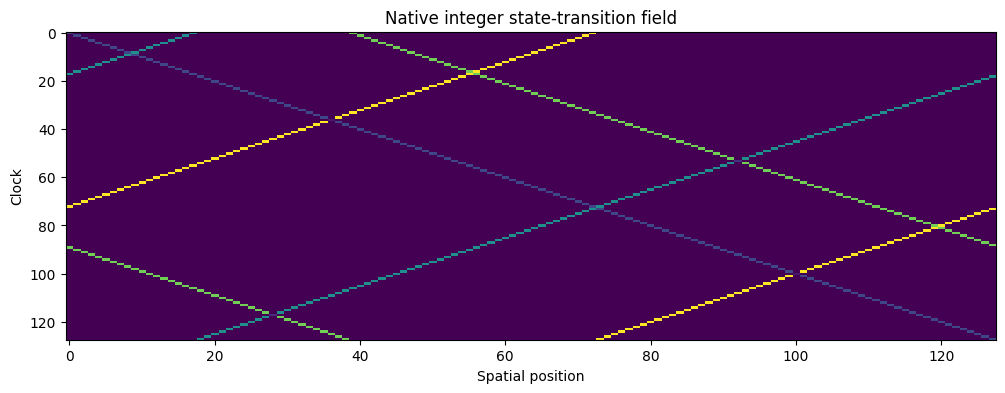

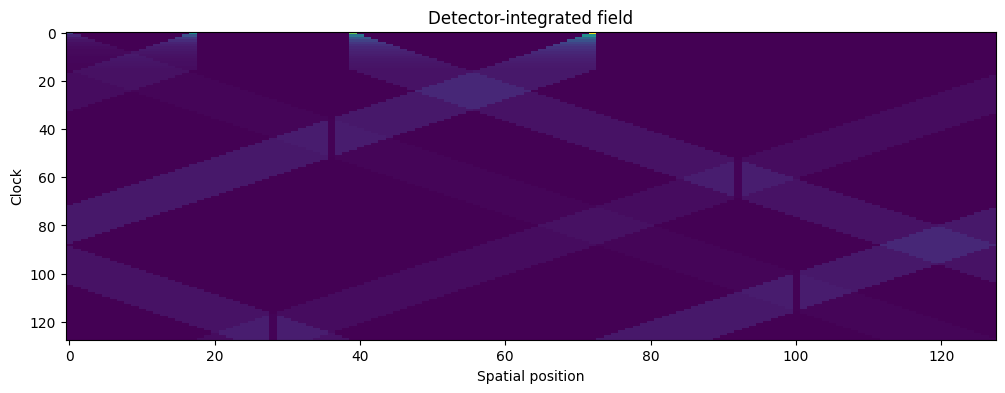

In [17]:

# Native ray rendering: show first 128 clocks and all spatial sites.
native = aggregate[:128]

fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(native, aspect="auto", interpolation="nearest")
ax.set_xlabel("Spatial position")
ax.set_ylabel("Clock")
ax.set_title("Native integer state-transition field")
plt.show()

# Temporal average over 16 clocks.
smooth = detector_average(native.astype(float), window=16)

fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(smooth, aspect="auto", interpolation="nearest")
ax.set_xlabel("Spatial position")
ax.set_ylabel("Clock")
ax.set_title("Detector-integrated field")
plt.show()



## 17. Collision trajectory plot


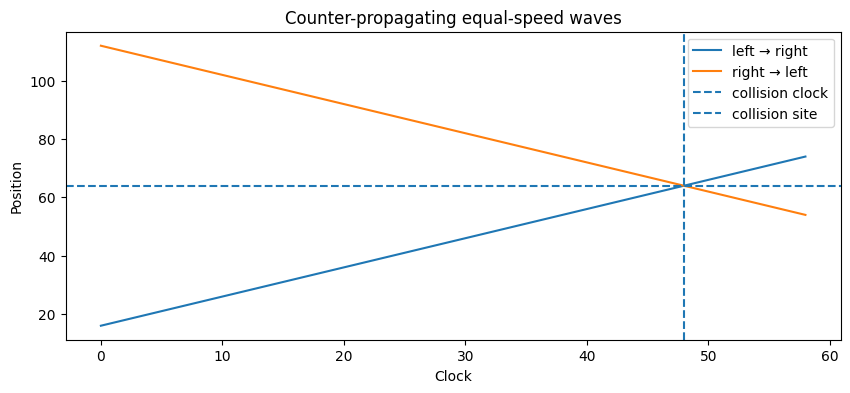

In [18]:

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(collision_df["t"], collision_df["left_x"], label="left → right")
ax.plot(collision_df["t"], collision_df["right_x"], label="right → left")
ax.axvline(tc, linestyle="--", label="collision clock")
ax.axhline(xc, linestyle="--", label="collision site")
ax.set_xlabel("Clock")
ax.set_ylabel("Position")
ax.set_title("Counter-propagating equal-speed waves")
ax.legend()
plt.show()



## 18. Reader-density transition

The next useful observable is not simply reader count but whether free translational gaps remain.

At \(m=N\):

\[
N-m=0.
\]

The substrate is completely occupied.

That is the regime in which a moving pattern cannot be represented as "one reader enters an empty site." It must be represented as a collective state/permutation transformation.


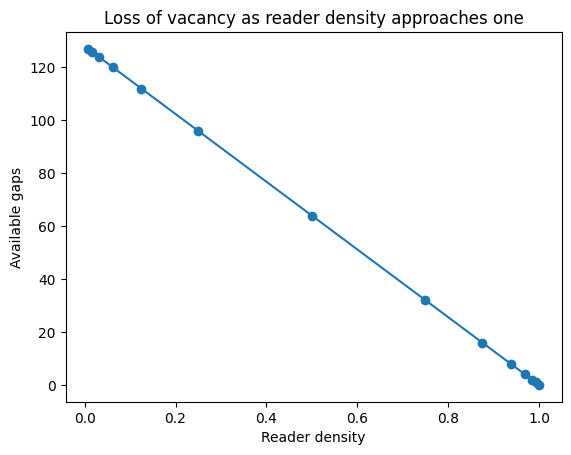

In [19]:

fig, ax = plt.subplots()
ax.plot(density_df["density"], density_df["available_gaps"], marker="o")
ax.set_xlabel("Reader density")
ax.set_ylabel("Available gaps")
ax.set_title("Loss of vacancy as reader density approaches one")
plt.show()



# 19. The core quantities to carry forward

The experiment now has separate exact state variables:

\[
\boxed{
O(x,t)=1
}
\]

for permanent occupancy,

\[
\boxed{
C(x,t)\in\{0,\ldots,15\}
}
\]

for local state/color,

\[
\boxed{
R_j(t)
}
\]

for reader trajectories,

\[
\boxed{
G(x,t)\in\{0,1\}
}
\]

for externally injected gaps,

and the collision residue

\[
\boxed{
C_{\rm coll}(a,b).
}
\]

The important measurements are:

\[
\partial_t C,
\qquad
\Delta_x C,
\qquad
R_j(t),
\qquad
G(x,t),
\qquad
\rho.
\]

The substrate can remain fixed while all of those fields evolve.

---

## Interpretation boundary

This is a discrete computational model.

It does **not** by itself establish that electromagnetic light, gravity, matter, or spacetime literally operate this way.

What it does give us is a serious test platform for the narrower proposition:

> A fully occupied field can support propagating, interacting, collision-generated, and apparently continuous wave states entirely through transformations of local state and relational phase.

The next extension is the spherical version: replace the one-dimensional ring with a closed spherical address graph, retain the same occupancy constraint, and allow counter-propagating geodesic/trajectory families to meet and transform.
